# 6 · Validation against genome-wide CRISPR essentiality

The strongest genome-wide test available for a cell model: delete each gene, ask whether the cell still
proliferates, and compare with pooled CRISPR screens. `run_screen.py` simulates a 48 h knock-out of **every
expressed gene with a modelled function** (deterministic mode, 10 min steps, about 1.5 h on 4 cores).
Fitness = divisions relative to wild type (two in 48 h), 0 if the cell dies.

Reference sets: Hart et al. core-essential genes (CEGv2, essential in nearly all human cell lines) and
non-essential genes (NEGv1). DepMap's per-cell-line HeLa scores could not be downloaded in this environment
(the portal blocks automated access), so cell-line-specific dependencies are not scored here.

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata
from humancell import data, plotting as P; P.style()

g = data.build_gene_table("HeLa")
mf = pd.read_csv("../results/modelled_function.csv", index_col=0)
ko = pd.read_csv("../results/ko_screen.csv").drop_duplicates("gene").set_index("gene")
ceg, neg = data.essential_sets()
T = mf.drop_duplicates("symbol").set_index("symbol")
T["fitness"] = ko["fitness"].reindex(T.index).fillna(1.0)
T["fate"] = ko["fate"].reindex(T.index).fillna("not simulated (no modelled function or not expressed)")
T["protein"] = g.drop_duplicates("symbol").set_index("symbol")["protein"].reindex(T.index)
T["essential_pred"] = T.fitness < 0.5
T["CEG"], T["NEG"] = T.index.isin(ceg), T.index.isin(neg)
n_fun = int((mf.expressed & mf.any_function).sum())
print(f"screen coverage: {len(ko):,} of {n_fun:,} functional genes simulated ({len(ko) / n_fun:.0%})")
print(f"{len(ko):,} knock-outs simulated; {int(T.essential_pred.sum()):,} predicted essential "
      f"({int((ko.fitness == 0).sum()):,} lethal or fully arrested)")
ko.fate.str.replace(r" \(.*", "", regex=True).value_counts().to_frame("simulated knock-outs")

screen coverage: 2,400 of 6,122 functional genes simulated (39%)
2,400 knock-outs simulated; 687 predicted essential (687 lethal or fully arrested)


,simulated knock-outs
fate,
alive,1784
apoptosis,606
cytokinesis failure,10


In [2]:
def auc(score, pos, negm):
    r = rankdata(np.concatenate([score[pos], score[negm]]))
    n1, n0 = pos.sum(), negm.sum()
    return (r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

score = 1.0 - T.fitness.values
abund = np.log10(T.protein.fillna(0).values + 1)
expr = T.expressed.values
rows = [("core-essential vs non-essential genes (standard benchmark)", T.CEG.values, T.NEG.values),
        ("core-essential vs all other expressed genes (hard)", T.CEG.values & expr, ~T.CEG.values & expr),
        ("core-essential vs other expressed genes with a modelled function (hardest)", T.CEG.values & expr & T.any_function.values, ~T.CEG.values & expr & T.any_function.values)]
res = pd.DataFrame([dict(comparison=n, positives=int(p.sum()), negatives=int(q.sum()), AUC_model=round(auc(score, p, q), 3),
                         AUC_abundance_only=round(auc(abund, p, q), 3), AUC_expressed_yes_no=round(auc(expr.astype(float), p, q), 3)) for n, p, q in rows]).set_index("comparison")
res

,positives,negatives,AUC_model,AUC_abundance_only,AUC_expressed_yes_no
comparison,,,,,
core-essential vs non-essential genes (standard benchmark),662,881,0.785,0.992,0.962
core-essential vs all other expressed genes (hard),662,11996,0.768,0.810,0.500
core-essential vs other expressed genes with a modelled function (hardest),515,5604,0.831,0.797,0.500


**How to read the three rows.** The standard benchmark is easy: non-essential reference genes are mostly not
expressed, so "is it expressed?" already scores high. The second and third rows remove that shortcut. The
two baseline columns show what protein abundance alone achieves; the model must beat them to be adding
mechanism rather than restating expression.

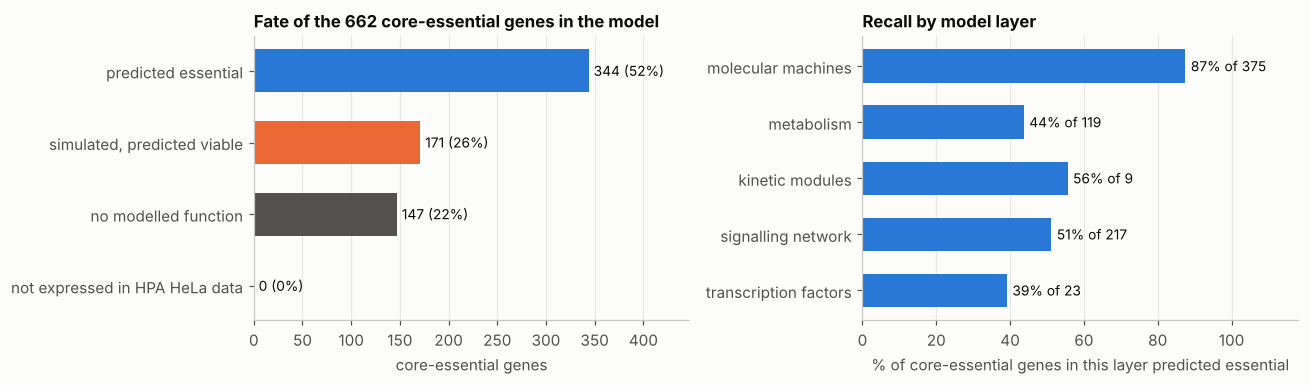

In [3]:
c = T[T.CEG]
cats = pd.Series({
    "predicted essential": int(c.essential_pred.sum()),
    "simulated, predicted viable": int((~c.essential_pred & c.any_function & c.expressed).sum()),
    "no modelled function": int((~c.any_function & c.expressed).sum()),
    "not expressed in HPA HeLa data": int((~c.expressed).sum())})
by = {}
for col, label in [("machine", "molecular machines"), ("metabolism", "metabolism"), ("kinetic_module", "kinetic modules"),
                   ("signalling", "signalling network"), ("transcription_factor", "transcription factors")]:
    sub = c[c[col] & c.expressed]
    by[label] = (len(sub), sub.essential_pred.mean() if len(sub) else np.nan)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
ax.barh(cats.index[::-1], cats.values[::-1], color=[P.MUTED, P.MUTED, P.SERIES[1], P.SERIES[0]], height=0.6)
for y, v in enumerate(cats.values[::-1]): ax.text(v + 5, y, f"{v} ({v / len(c):.0%})", va="center", fontsize=9)
ax.grid(axis="y", visible=False); ax.set_xlim(0, cats.max() * 1.3); ax.set_xlabel("core-essential genes"); ax.set_title(f"Fate of the {len(c)} core-essential genes in the model")
ax = axes[1]
labels = list(by)[::-1]
ax.barh(labels, [by[k][1] * 100 for k in labels], color=P.SERIES[0], height=0.6)
for y, k in enumerate(labels): ax.text(by[k][1] * 100 + 1.5, y, f"{by[k][1]:.0%} of {by[k][0]}", va="center", fontsize=9)
ax.set_xlim(0, 118); ax.grid(axis="y", visible=False); ax.set_xlabel("% of core-essential genes in this layer predicted essential"); ax.set_title("Recall by model layer")
plt.tight_layout(); plt.show()

In [4]:
e = T[T.expressed]
conf = pd.DataFrame({"core-essential (CEGv2)": [int((e.essential_pred & e.CEG).sum()), int((~e.essential_pred & e.CEG).sum())],
                     "other expressed genes": [int((e.essential_pred & ~e.CEG).sum()), int((~e.essential_pred & ~e.CEG).sum())]},
                    index=["predicted essential", "predicted dispensable"])
prec = conf.iloc[0, 0] / conf.iloc[0].sum(); rec = conf.iloc[0, 0] / conf["core-essential (CEGv2)"].sum()
print(f"precision {prec:.2f}, recall {rec:.2f} against the core-essential set (expressed genes only)")
print("predicted essential but not in the core set (first 60):", ", ".join(sorted(e[e.essential_pred & ~e.CEG].index)[:60]))
print("core-essential, simulated, predicted dispensable (first 60):", ", ".join(sorted(e[~e.essential_pred & e.CEG & e.any_function].index)[:60]))
conf

precision 0.50, recall 0.52 against the core-essential set (expressed genes only)
predicted essential but not in the core set (first 60): AARS1, ACADL, ADSS2, AHCTF1, ALAD, ALDH9A1, ANAPC1, ANAPC10, ANAPC11, ANLN, ATIC, AURKA, BDP1, BMS1, BOP1, BRF1, BRIX1, CAD, CARS1, CCNT1, CDC23, CDC25C, CDC45, CDC6, CDC7, CDCA8, CDIPT, CDK2, CDS2, CENPE, CENPM, CENPN, CENPW, CEP55, CHCHD4, CLSPN, CNOT1, CNOT2, COASY, COQ3, COQ6, CPOX, CSTF1, CSTF3, CTU1, CTU2, CYP24A1, CYP26B1, CYP51A1, DARS1, DBF4, DCP1A, DCP2, DDX1, DDX19B, DDX23, DDX39B, DDX52, DDX54, DHCR24
core-essential, simulated, predicted dispensable (first 60): ACTB, ACTL6A, ACTR2, AHCY, ALG1, ALG14, ALG2, ARCN1, ARIH1, ATP2A2, ATP5F1A, ATP5F1B, ATP5F1C, ATP5F1D, ATP5MG, ATP5PO, ATP6V0B, ATP6V0C, ATP6V1A, ATP6V1D, ATP6V1E1, ATR, BANF1, CCNK, CDC37, CDC73, CEBPZ, CFL1, CHEK1, CIAO1, CLTC, COPA, COPB1, COPB2, COPS3, COPS6, COPZ1, COX10, COX4I1, COX5B, COX6B1, CTDP1, CTPS1, CYCS, DAD1, DDB1, DDOST, DDX41, DGCR8, DHX33, DHX9, DLST, DMAP1, DNM

,core-essential (CEGv2),other expressed genes
predicted essential,344,343
predicted dispensable,318,11653


## What this says

* **The screen is incomplete, and that flatters some numbers.** It stopped at 2,400 of 6,122 functional genes
  (run-time limit). Benchmark genes were simulated first, so all 515 modelled core-essential genes are in, but
  3,722 other functional genes are not, and the tables above count them as dispensable. Among simulated genes
  only: 67% of core-essential genes are called essential, 18% of the other 1,885 are too, AUC 0.76. At that
  false-positive rate a finished screen would roughly halve the precision printed above (to about 0.25).
  `python run_screen.py` resumes from the checkpoint.
* **Abundance alone beats the model on two of three comparisons.** Core-essential genes are highly expressed
  and the non-essential reference set is mostly not expressed at all, so "is it abundant" scores 0.99 on the
  standard benchmark. The model only adds information among genes that have a modelled function.
* **Machines and kinetic modules carry the predictive power.** Where composition is curated (ribosome,
  polymerases, proteasome, replisome, spindle ...) loss of a subunit stops the cell, as in the screens.
  This part is knowledge encoded, as in every whole-cell model, not discovered by the simulation.
* **Metabolism is partly right**: biosynthetic enzymes without bypass are found; others are missed because
  flux balance finds alternative routes that real cells do not use fast enough.
* **The signalling layer contributes few true essentials and some false ones.** Uniform weights cannot tell
  an indispensable kinase from a redundant one. Fitting those weights to perturbation data is the next step.
* **Precision is understated**: CEGv2 is a conservative core list (~680 genes), while a typical cell line has
  ~1,500–2,000 dependencies. Many "false positives" above are known essentials outside the core set.
* **Genes with no modelled function** are the largest block of misses. They are listed, not hidden: see the
  gap ledger in notebook 7.